In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
DRIVE_PATH = "/content/drive/MyDrive/Capstone/"

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
import shap

# CSVs live directly in Capstone/; models live in Capstone/models/
DATA_PATH = "/content/drive/MyDrive/Capstone/"
MODELS_PATH = "/content/drive/MyDrive/Capstone/models/"

X_train = pd.read_csv(DATA_PATH + "X_train_clean.csv")
X_test = pd.read_csv(DATA_PATH + "X_test_clean.csv")
y_train = pd.read_csv(DATA_PATH + "y_train_clean.csv").squeeze()
y_test = pd.read_csv(DATA_PATH + "y_test_clean.csv").squeeze()

best_lr_model = joblib.load(MODELS_PATH + "logistic_regression_pipeline.pkl")
best_rf_model = joblib.load(MODELS_PATH + "random_forest_pipeline.pkl")
best_xgb_model = joblib.load(MODELS_PATH + "xgboost_pipeline.pkl")

print("Everything loaded successfully")

Everything loaded successfully


In [ ]:
print("LR:", best_lr_model.named_steps["clf"].get_params()["C"], best_lr_model.named_steps["clf"].get_params()["l1_ratio"])
print("RF:", best_rf_model.named_steps["clf"].get_params()["max_depth"], best_rf_model.named_steps["clf"].get_params()["n_estimators"])
print("XGB:", best_xgb_model.named_steps["clf"].get_params()["max_depth"], best_xgb_model.named_steps["clf"].get_params()["learning_rate"])

LR: 1 0.9
RF: 5 100
XGB: 3 0.01


In [ ]:

rf_classifier = best_rf_model.named_steps["clf"]
xgb_classifier = best_xgb_model.named_steps["clf"]


rf_explainer = shap.TreeExplainer(rf_classifier)
xgb_explainer = shap.TreeExplainer(xgb_classifier)

rf_shap_values = rf_explainer(X_test)
xgb_shap_values = xgb_explainer(X_test)

print("Tree explainers ready")

Tree explainers ready


In [ ]:
lr_scaler = best_lr_model.named_steps["scaler"]
lr_classifier = best_lr_model.named_steps["clf"]

X_test_scaled_for_shap = pd.DataFrame(
    lr_scaler.transform(X_test),
    columns=X_test.columns
)

lr_explainer = shap.LinearExplainer(lr_classifier, X_test_scaled_for_shap)
lr_shap_values = lr_explainer(X_test_scaled_for_shap)

print("Linear explainer ready")

Linear explainer ready


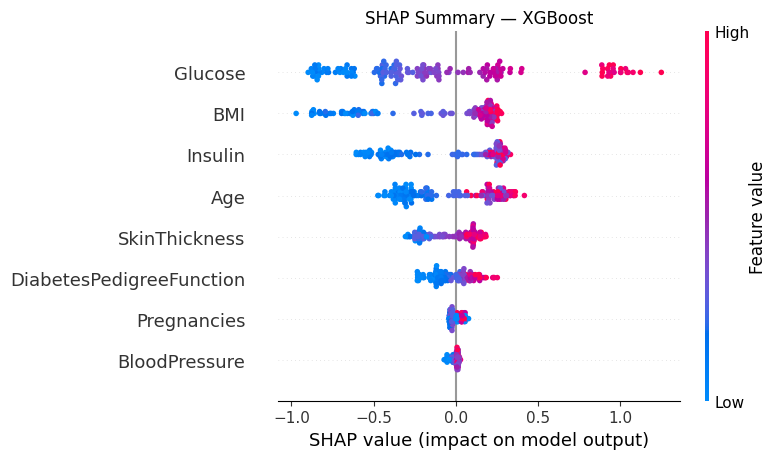

In [ ]:
shap.plots.beeswarm(xgb_shap_values, show=False)
plt.title("SHAP Summary — XGBoost")
plt.tight_layout()
plt.show()

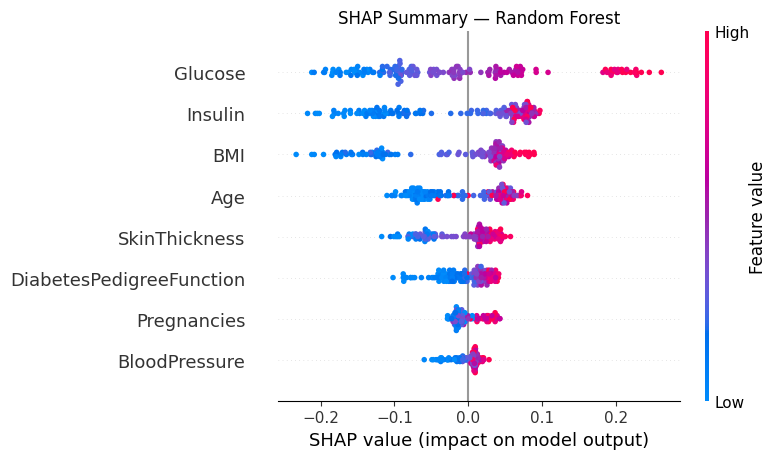

In [ ]:
shap.plots.beeswarm(rf_shap_values[:, :, 1], show=False)
plt.title("SHAP Summary — Random Forest")
plt.tight_layout()
plt.show()

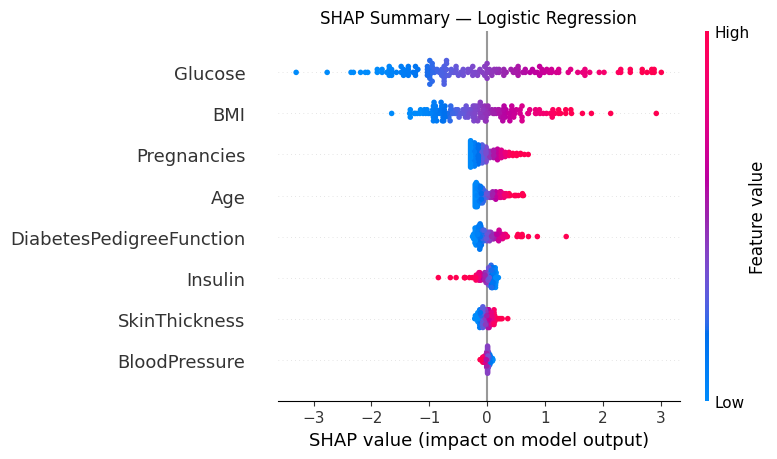

In [ ]:
shap.plots.beeswarm(lr_shap_values, show=False)
plt.title("SHAP Summary — Logistic Regression")
plt.tight_layout()
plt.show()

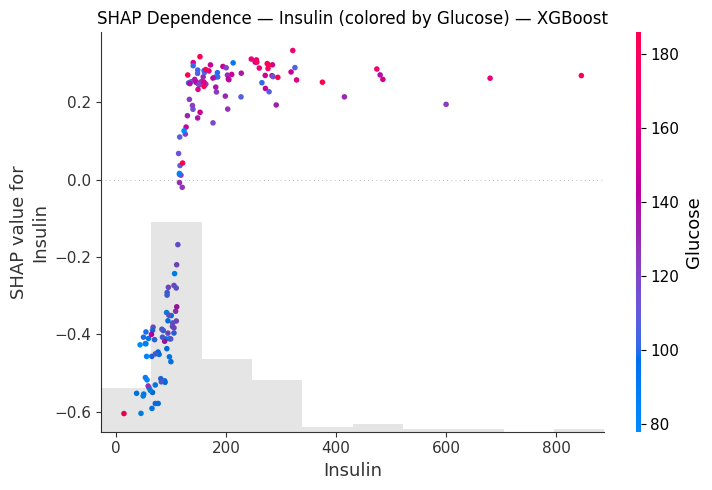

In [ ]:
shap.plots.scatter(xgb_shap_values[:, "Insulin"], color=xgb_shap_values[:, "Glucose"], show=False)
plt.title("SHAP Dependence: Insulin (colored by Glucose) — XGBoost")
plt.tight_layout()
plt.show()

Moving to local explanations: pick a specific patient (ideally one where Insulin and Glucose disagree in an interesting way — e.g., high Insulin but low Glucose) and generate a waterfall plot for them specifically.

In [ ]:
# XGBoost's predictions for the test set
y_pred_xgb = best_xgb_model.predict(X_test)
y_prob_xgb = best_xgb_model.predict_proba(X_test)[:, 1]

Find a genuinely interesting patient where Insulin and Glucose disagree

In [ ]:
# Find patients with high Insulin but comparatively low/moderate Glucose
interesting_cases = X_test[(X_test["Insulin"] > 200) & (X_test["Glucose"] < 130)]
print(interesting_cases)
print("\nIndices to consider:", interesting_cases.index.tolist())

     Pregnancies  Glucose  BloodPressure  SkinThickness     Insulin   BMI  \
20           3.0    128.0           78.0      22.145730  202.754825  21.1   
42           2.0    108.0           62.0      10.000000  278.000000  25.3   
56          10.0    129.0           62.0      36.000000  202.251717  41.2   
89           0.0    114.0           80.0      34.000000  285.000000  44.2   
92           7.0    106.0           92.0      18.000000  226.935827  22.7   
102          5.0    105.0           72.0      29.000000  325.000000  36.9   
112          8.0    124.0           76.0      24.000000  600.000000  28.7   
114          2.0    124.0           68.0      28.000000  205.000000  32.9   
122          8.0     91.0           82.0      30.498212  212.585131  35.6   
136          2.0    101.0           58.0      17.000000  265.000000  24.2   

     DiabetesPedigreeFunction   Age  
20                      0.268  55.0  
42                      0.881  22.0  
56                      0.441  38.0  


**Before Comparing the ten candidates**

In [ ]:
# Picking a patient
patient_idx = interesting_cases.index[4]   # change [0] to pick a different one if several show up

print("Patient's actual feature values:")
print(X_test.loc[patient_idx])
print("\nActual outcome:", y_test.loc[patient_idx])
print("XGBoost predicted probability of diabetes:", y_prob_xgb[X_test.index.get_loc(patient_idx)])
print("XGBoost predicted class:", y_pred_xgb[X_test.index.get_loc(patient_idx)])

Patient's actual feature values:
Pregnancies                   7.000000
Glucose                     106.000000
BloodPressure                92.000000
SkinThickness                18.000000
Insulin                     226.935827
BMI                          22.700000
DiabetesPedigreeFunction      0.235000
Age                          48.000000
Name: 92, dtype: float64

Actual outcome: 0
XGBoost predicted probability of diabetes: 0.27315435
XGBoost predicted class: 0


**Generating the waterfall plot for this patient**

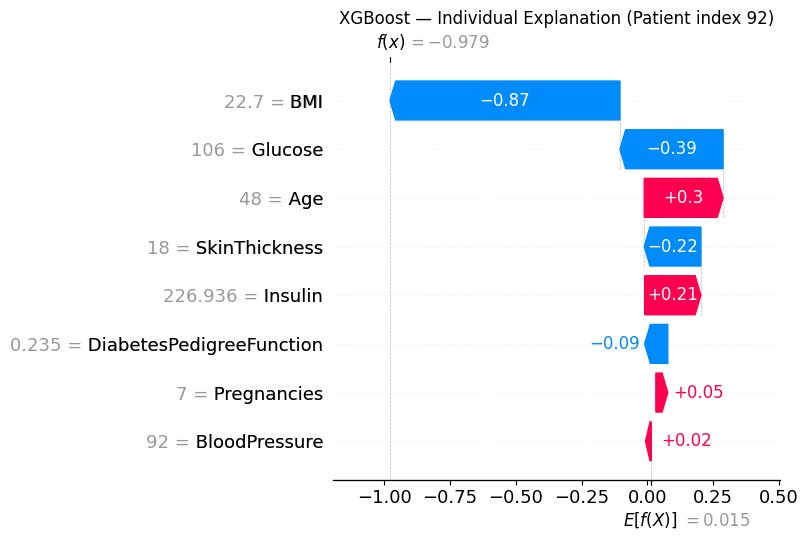

In [ ]:
# Convert the DataFrame index to a positional index, since SHAP values
# are stored as a plain array aligned to X_test's row order, not its labels
pos_idx = X_test.index.get_loc(patient_idx)

shap.plots.waterfall(xgb_shap_values[pos_idx], show=False)
plt.title(f"XGBoost — Individual Explanation (Patient index {patient_idx})")
plt.tight_layout()
plt.show()

How to read this: it starts at E[f(x)] (the model's baseline, average prediction across the dataset), then stacks each feature's SHAP contribution one at a time  red bars push the prediction up toward diabetic, blue bars push it down ending at f(x), this specific patient's final predicted value. Given what we just saw in the dependence plot, I'd expect Insulin to show up with a small or even negative contribution here specifically because this patient's Glucose is comparatively low, that would be a clean, concrete illustration of the interaction effect for a single real case, in your own patient's numbers rather than an abstract scatter plot.

False negative — patient index: 3
Pregnancies                   7.000000
Glucose                     114.000000
BloodPressure                64.000000
SkinThickness                31.460707
Insulin                     139.494895
BMI                          27.400000
DiabetesPedigreeFunction      0.732000
Age                          34.000000
Name: 3, dtype: float64

Actual outcome: 1 | Predicted probability: 0.4762636


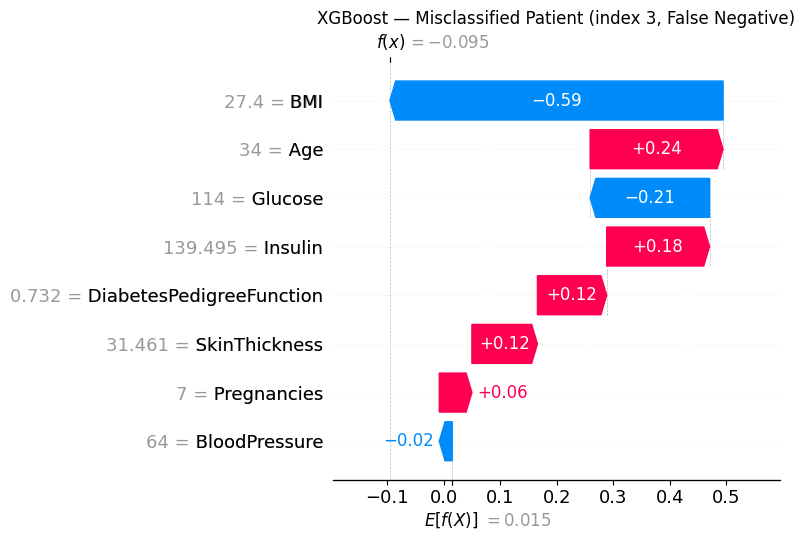

In [ ]:
# Find a false negative: actually diabetic, but XGBoost predicted non-diabetic
y_test_reset = y_test.reset_index(drop=True)
false_negative_positions = np.where((y_test_reset.values == 1) & (y_pred_xgb == 0))[0]

if len(false_negative_positions) > 0:
    fn_pos = false_negative_positions[0]
    fn_idx = X_test.index[fn_pos]
    print("False negative — patient index:", fn_idx)
    print(X_test.loc[fn_idx])
    print("\nActual outcome:", y_test.loc[fn_idx], "| Predicted probability:", y_prob_xgb[fn_pos])

    shap.plots.waterfall(xgb_shap_values[fn_pos], show=False)
    plt.title(f"XGBoost — Misclassified Patient (index {fn_idx}, False Negative)")
    plt.tight_layout()
    plt.show()
else:
    print("No false negatives found for XGBoost on this test set.")

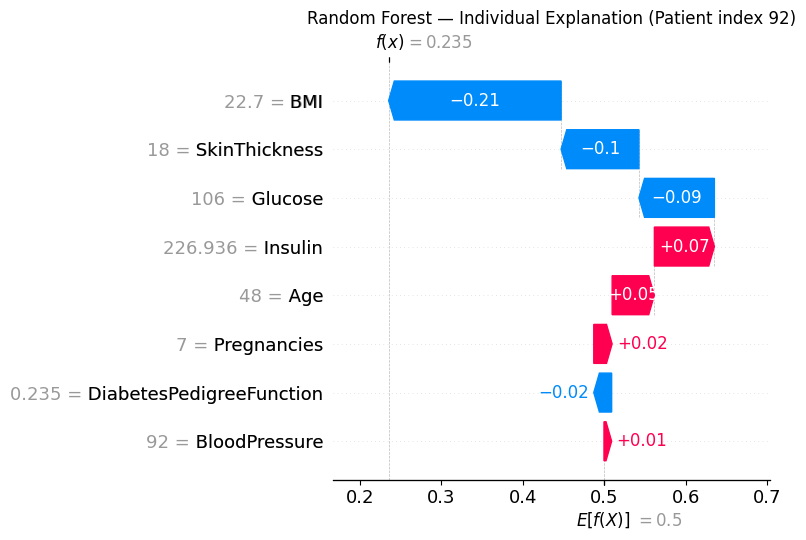

In [ ]:
shap.plots.waterfall(rf_shap_values[pos_idx, :, 1], show=False)
plt.title(f"Random Forest — Individual Explanation (Patient index {patient_idx})")
plt.tight_layout()
plt.show()

In [ ]:
# Compare all 10 candidates side by side to pick the clearest example
candidates = [20, 42, 56, 89, 92, 102, 112, 114, 122, 136]

comparison = X_test.loc[candidates, ["Insulin", "Glucose", "BMI", "Age"]].copy()
comparison["Actual_Outcome"] = y_test.loc[candidates].values
comparison["Predicted_Prob"] = [y_prob_xgb[X_test.index.get_loc(i)] for i in candidates]
comparison["Predicted_Class"] = [y_pred_xgb[X_test.index.get_loc(i)] for i in candidates]

print(comparison.sort_values("Insulin", ascending=False))

        Insulin  Glucose   BMI   Age  Actual_Outcome  Predicted_Prob  \
112  600.000000    124.0  28.7  52.0               1        0.549106   
102  325.000000    105.0  36.9  28.0               0        0.410422   
89   285.000000    114.0  44.2  27.0               0        0.476858   
42   278.000000    108.0  25.3  22.0               0        0.187073   
136  265.000000    101.0  24.2  23.0               0        0.172240   
92   226.935827    106.0  22.7  48.0               0        0.273154   
122  212.585131     91.0  35.6  68.0               0        0.520055   
114  205.000000    124.0  32.9  30.0               1        0.628630   
20   202.754825    128.0  21.1  55.0               0        0.269134   
56   202.251717    129.0  41.2  38.0               1        0.714316   

     Predicted_Class  
112                1  
102                0  
89                 0  
42                 0  
136                0  
92                 0  
122                1  
114                1  


In [ ]:
patient_idx = 112

print("Patient's actual feature values:")
print(X_test.loc[patient_idx])
print("\nActual outcome:", y_test.loc[patient_idx])
print("XGBoost predicted probability of diabetes:", y_prob_xgb[X_test.index.get_loc(patient_idx)])
print("XGBoost predicted class:", y_pred_xgb[X_test.index.get_loc(patient_idx)])

Patient's actual feature values:
Pregnancies                   8.000
Glucose                     124.000
BloodPressure                76.000
SkinThickness                24.000
Insulin                     600.000
BMI                          28.700
DiabetesPedigreeFunction      0.687
Age                          52.000
Name: 112, dtype: float64

Actual outcome: 1
XGBoost predicted probability of diabetes: 0.5491057
XGBoost predicted class: 1


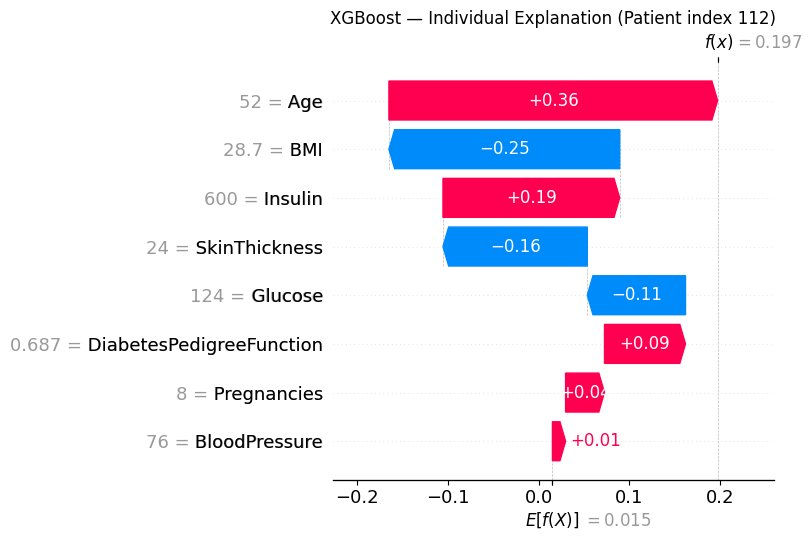

In [ ]:
pos_idx = X_test.index.get_loc(patient_idx)

shap.plots.waterfall(xgb_shap_values[pos_idx], show=False)
plt.title(f"XGBoost — Individual Explanation (Patient index {patient_idx})")
plt.tight_layout()
plt.show()

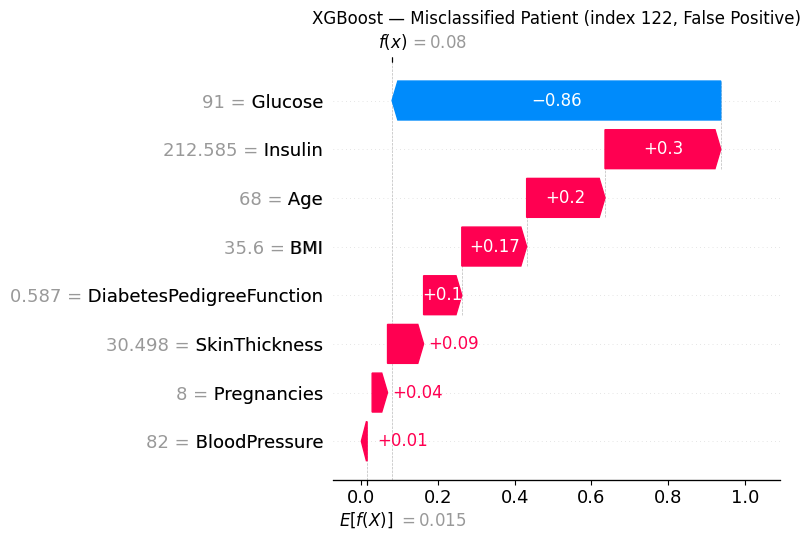

In [ ]:
pos_idx = X_test.index.get_loc(patient_idx)

shap.plots.waterfall(xgb_shap_values[pos_idx], show=False)
plt.title(f"XGBoost — Misclassified Patient (index {patient_idx}, False Positive)")
plt.tight_layout()
plt.show()